# Project 13: Symbolic Autograd & Higher-Order Derivatives

This project explores NeuroGebra's symbolic mathematical engine and automatic differentiation.
We demonstrate exact symbolic differentiation, Jacobian computation, Hessian matrices, and vector field plotting.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
try:
    from IPython.display import display, Math, Latex
    HAS_IPYTHON = True
except ImportError:
    HAS_IPYTHON = False
from neurogebra.core.expression import Expression
from neurogebra.core.forge import MathForge

forge = MathForge()
print("[INFO] MathForge symbolic engine loaded.")


[INFO] MathForge symbolic engine loaded.


In [2]:
# Define non-convex 2D objective function: Himmelblau's function
# f(x, y) = (x^2 + y - 11)^2 + (x + y^2 - 7)^2
f_expr = Expression(
    name='himmelblau',
    symbolic_expr='(x**2 + y - 11)**2 + (x + y**2 - 7)**2',
)

# First-order derivatives (Gradients)
grad_x = f_expr.gradient('x')
grad_y = f_expr.gradient('y')

# Second-order derivatives (Hessian components)
hess_xx = grad_x.gradient('x')
hess_yy = grad_y.gradient('y')
hess_xy = grad_x.gradient('y')

if HAS_IPYTHON:
    display(Math(r"f(x, y) = " + f_expr.latex()))
    display(Math(r"\frac{\partial f}{\partial x} = " + grad_x.latex()))
    display(Math(r"\frac{\partial f}{\partial y} = " + grad_y.latex()))
    display(Math(r"\frac{\partial^2 f}{\partial x^2} = " + hess_xx.latex()))
    display(Math(r"\frac{\partial^2 f}{\partial y^2} = " + hess_yy.latex()))
    display(Math(r"\frac{\partial^2 f}{\partial x \partial y} = " + hess_xy.latex()))
else:
    print(f"f(x, y)   = {f_expr.latex()}")
    print(f"df/dx     = {grad_x.latex()}")
    print(f"df/dy     = {grad_y.latex()}")
    print(f"d2f/dx2   = {hess_xx.latex()}")
    print(f"d2f/dy2   = {hess_yy.latex()}")
    print(f"d2f/dxdy  = {hess_xy.latex()}")


f(x, y) = (x + y**2 - 7)**2 + (x**2 + y - 11)**2

df/dx = 4*x*(x**2 + y - 11) + 2*x + 2*y**2 - 14

df/dy = 2*x**2 + 4*y*(x + y**2 - 7) + 2*y - 22

d2f/dx2 = 12*x**2 + 4*y - 42

d2f/dy2 = 4*x + 12*y**2 - 26

d2f/dxdy = 4*x + 4*y

In [3]:
# Evaluate Gradient and Hessian at test point (3, 2)
pt = {'x': 3.0, 'y': 2.0}
val = float(f_expr.eval(x=3.0, y=2.0))
gx = float(grad_x.eval(x=3.0, y=2.0))
gy = float(grad_y.eval(x=3.0, y=2.0))
H = np.array([
    [float(hess_xx.eval(x=3.0, y=2.0)), float(hess_xy.eval(x=3.0, y=2.0))],
    [float(hess_xy.eval(x=3.0, y=2.0)), float(hess_yy.eval(x=3.0, y=2.0))],
])
det_H = float(np.linalg.det(H))

if HAS_IPYTHON:
    display(Math(rf"f(3, 2) = {val:.4f}"))
    display(Math(rf"\nabla f(3, 2) = \begin{{bmatrix}} {gx:.4f} \\ {gy:.4f} \end{{bmatrix}}"))
    display(Math(r"\mathbf{H}(3, 2) = \begin{bmatrix} " + f"{H[0,0]:.4f} & {H[0,1]:.4f} \\ {H[1,0]:.4f} & {H[1,1]:.4f}" + r" \end{bmatrix}"))
    display(Math(rf"\det(\mathbf{{H}}(3, 2)) = {det_H:.4f}"))
else:
    print(f"f(3, 2)               = {val:.4f}")
    print(f"Gradient [gx, gy]     = [{gx:.4f}, {gy:.4f}]")
    print("Hessian Matrix H:\n", H)
    print(f"Hessian Determinant   = {det_H:.4f}")


f(3, 2) = 0.0000

Gradient [gx, gy] = [0.0000, 0.0000]

Hessian Matrix H:
 [[74. 20.]
 [20. 34.]]

Hessian Determinant = 2116.0000

<string>:23: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


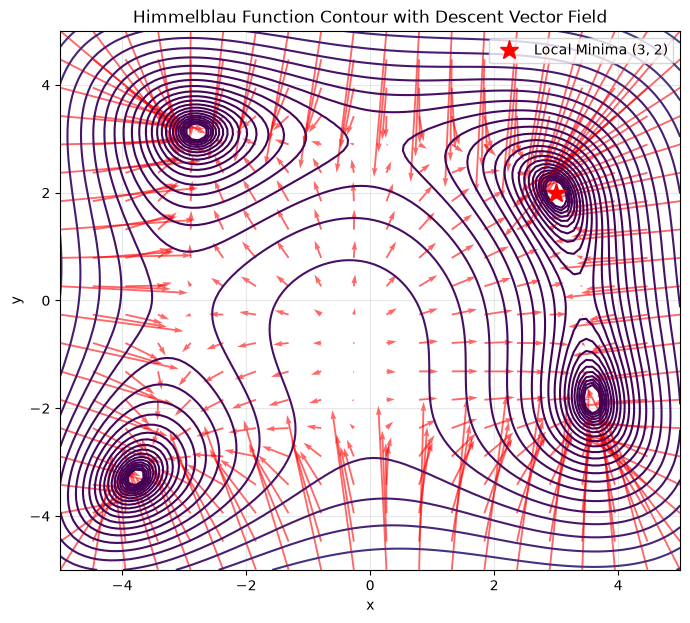

In [4]:
# 2D Contour and Gradient Vector Field Visualization
x_vals = np.linspace(-5, 5, 100)
y_vals = np.linspace(-5, 5, 100)
X_grid, Y_grid = np.meshgrid(x_vals, y_vals)
Z = (X_grid**2 + Y_grid - 11)**2 + (X_grid + Y_grid**2 - 7)**2

# Coarse grid for quiver gradient vectors
x_c = np.linspace(-5, 5, 20)
y_c = np.linspace(-5, 5, 20)
Xc, Yc = np.meshgrid(x_c, y_c)
U = 4 * Xc * (Xc**2 + Yc - 11) + 2 * (Xc + Yc**2 - 7)
V = 2 * (Xc**2 + Yc - 11) + 4 * Yc * (Xc + Yc**2 - 7)

plt.figure(figsize=(8, 7))
plt.contour(X_grid, Y_grid, Z, levels=np.logspace(0, 3.5, 30), cmap='viridis')
plt.quiver(Xc, Yc, -U, -V, color='red', alpha=0.6, scale=1500)
plt.plot(3.0, 2.0, 'r*', markersize=14, label='Local Minima (3, 2)')
plt.title('Himmelblau Function Contour with Descent Vector Field')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()
